## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

# Importing modules from src
from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import evaluate, sparse_fit, fit
from src.mSHRED.mSRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Load Data and Measurement

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

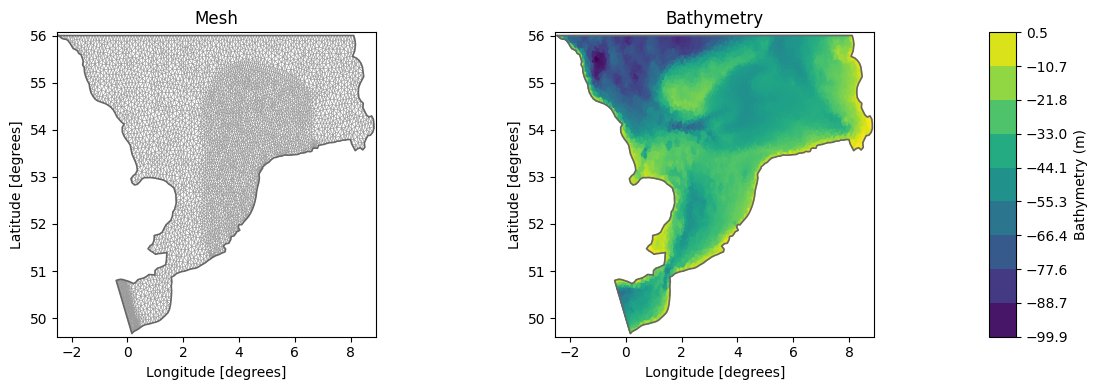

In [4]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

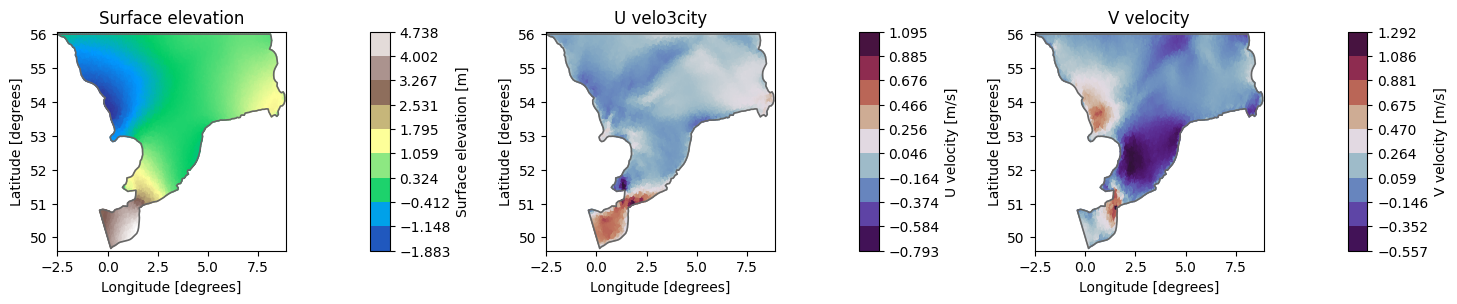

In [5]:
# plot a simulation
ds = dfs.read(time = slice("2022-01-01", "2023-10-30"))

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velo3city", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()


## Available Sensors

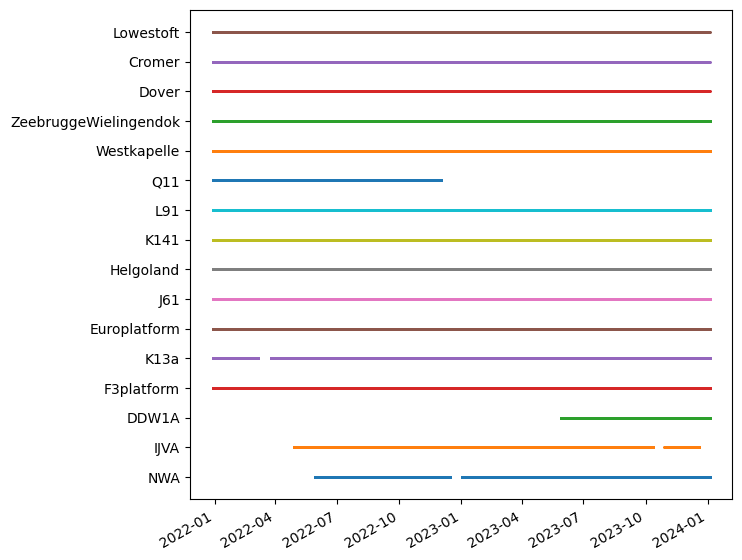

In [6]:
# sensor coverage

wllist = get_wl_point_obs()      # get water level point observations
#altlist = get_altimetry_obs()   # get altimetry observations (not used in this example, but can be included for training)

# high fidelity observations 
high_fidelity = ["Dover", "ZeebruggeWielingendok", "NWA", "K141"]

# combine all observations and filter for high fidelity ones
alllist = wllist #+ altlist

#alllist = [obs for obs in alllist if obs.name in high_fidelity]   # filter for high fidelity observations (optional, can be used to focus on specific sensors)

#plot temporal coverage of observations
ms.plotting.temporal_coverage(alllist)
plt.show()

Total stations: 16
Stations with full temporal coverage: 6
Intermittent stations: 10


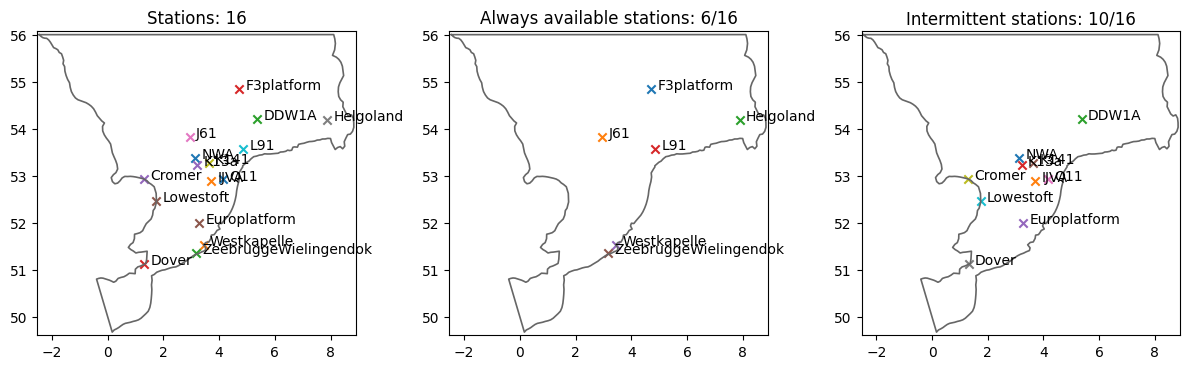

In [7]:
# Select stations with full temporal coverage

stations = []
available_stations = []
intermittent = []
for i in range(len(alllist)):
    stations.append(alllist[i])
    if ds.time.isin(alllist[i].time).all():
        available_stations.append(alllist[i])
    else:
        intermittent.append(alllist[i])

print(f"Total stations: {len(stations)}")
print(f"Stations with full temporal coverage: {len(available_stations)}")
print(f"Intermittent stations: {len(intermittent)}")

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(available_stations, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(available_stations)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intermittent stations: {len(intermittent)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [8]:
# Extract water level measurements
measurements = extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr)

In [9]:
# Extract the values and convert to torch tensors

# remove nans from H, U, V 
dsH = dsH.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsU = dsU.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsV = dsV.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]

# outputs
H = torch.tensor(dsH, dtype=torch.float32)
U = torch.tensor(dsU, dtype=torch.float32)
V = torch.tensor(dsV, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

# free memory
del dsH, dsU, dsV

H shape: torch.Size([32064, 8533])
U shape: torch.Size([32064, 8533])
V shape: torch.Size([32064, 8533])
Measurements shape: torch.Size([32064, 16])


In [10]:
# Extract measurements for always-available stations only
av_indices = [stations.index(s) for s in available_stations]
measurements_av = measurements[:, av_indices]

time_steps, _ = measurements_av.shape

# Count NaNs for intermittent stations
intermittent_indices = [stations.index(s) for s in intermittent]
nan_counts_intermittent = np.isnan(measurements[:, intermittent_indices].numpy()).sum(axis=0)

# Build a clean coverage table and sort by coverage percentage
rows = []
for i, s in enumerate(intermittent):
    ok_count = int(time_steps - nan_counts_intermittent[i])
    nan_count = int(nan_counts_intermittent[i])
    coverage = 100 * ok_count / time_steps
    rows.append({
        "station": s.name,
        "ok": ok_count,
        "nans": nan_count,
        "coverage_%": round(coverage, 1),
    })
coverage_df = pd.DataFrame(rows).sort_values("coverage_%", ascending=False).reset_index(drop=True)

print(f"Intermittent stations ({len(intermittent)}):")
display(coverage_df.style.format({"ok": "{:,}", "nans": "{:,}", "coverage_%": "{:.1f}"}))

Intermittent stations (10):


,station,ok,nans,coverage_%
0,K141,"31,997",67,99.8
1,Europlatform,"31,629",435,98.6
2,K13a,"30,913","1,151",96.4
3,IJVA,"24,659","7,405",76.9
4,NWA,"23,603","8,461",73.6
5,Q11,"15,900","16,164",49.6
6,Dover,"15,555","16,509",48.5
7,Lowestoft,"15,510","16,554",48.4
8,Cromer,"15,399","16,665",48.0
9,DDW1A,"6,968","25,096",21.7


## Hyperparameters

In [11]:
ERRORS = []

# DataManager
LAGS = 48

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 500        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 100           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

SPARSE_FACTOR = 4        # max nuber of observations to use per time step during training (for sparse training)
SPARSE_LOG = True        # whether to log the sparse training process (e.g., which observations are used at each step)

# Architecture
ENCODER_DEPTH = 3               # number of encoder layers
HIDDEN_SIZE = 64                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 96            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [100]    # hidden sizes for decoder layers 
DROPOUT = 0.0                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## (T.0): only available sensors

In [12]:
# Keep only sensors that never contain NaNs over time
nan_sensor_mask = torch.isnan(measurements).any(dim=0)
measurements_av = measurements[:, ~nan_sensor_mask]

kept_sensor_indices = torch.where(~nan_sensor_mask)[0]
removed_sensor_indices = torch.where(nan_sensor_mask)[0]

# print the shape of the arrays
print("\nAfter selecting always-available stations only:")
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements_av.shape)


After selecting always-available stations only:
H shape: torch.Size([32064, 8533])
U shape: torch.Size([32064, 8533])
V shape: torch.Size([32064, 8533])
Measurements shape: torch.Size([32064, 6])


In [13]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = COMPRESS_H, measurements = measurements_av)
manager.add_data(U, id = "U velocity", compress = COMPRESS_U)
manager.add_data(V, id = "V velocity", compress = COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1] 
nn_output_shape = train_dataset[0][1].shape[0]  
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1669 %
Residual energy of U velocity after keeping 40 modes: 0.1940 %
Residual energy of V velocity after keeping 68 modes: 0.1850 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([25651, 48, 6]) -> torch.Size([25651, 120])
Val:	 torch.Size([3206, 48, 6]) -> torch.Size([3206, 120])
Test:	 torch.Size([3207, 48, 6]) -> torch.Size([3207, 120])

Input shape for the model: 6
Output shape for the model: 120


Starting training...


Training:  25%|██▌       | 126/500 [21:04<1:02:33, 10.04s/it, Train Loss=0.00133, Val Loss=0.00448, Patience=99, Best Val Loss=0.00381, LR=8.49e-04]

Early stopping at epoch 127
Training completed with best validation loss: 0.0038


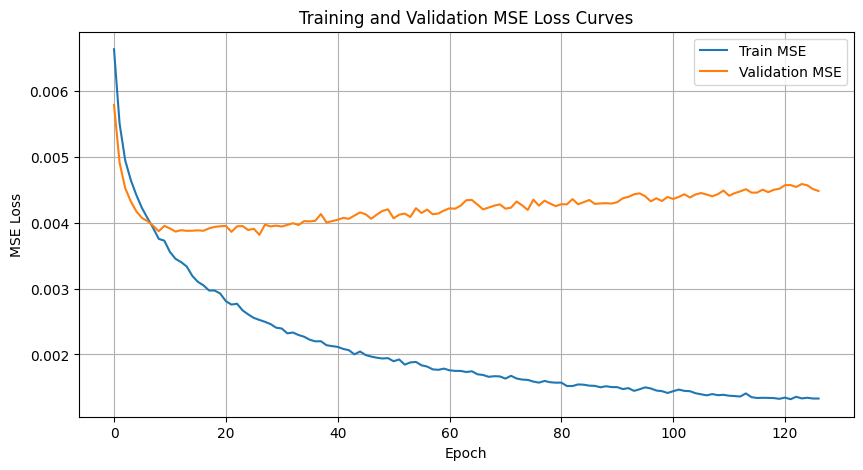

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.002524,0.003814,0.006619,0.103981,0.121077,0.150981


In [14]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels = False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset, 
    model = f"(mSHRED): TR+{DECODER}", type="(T.0): always-available stations only"
)

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.0)_always-available_stations_only.png


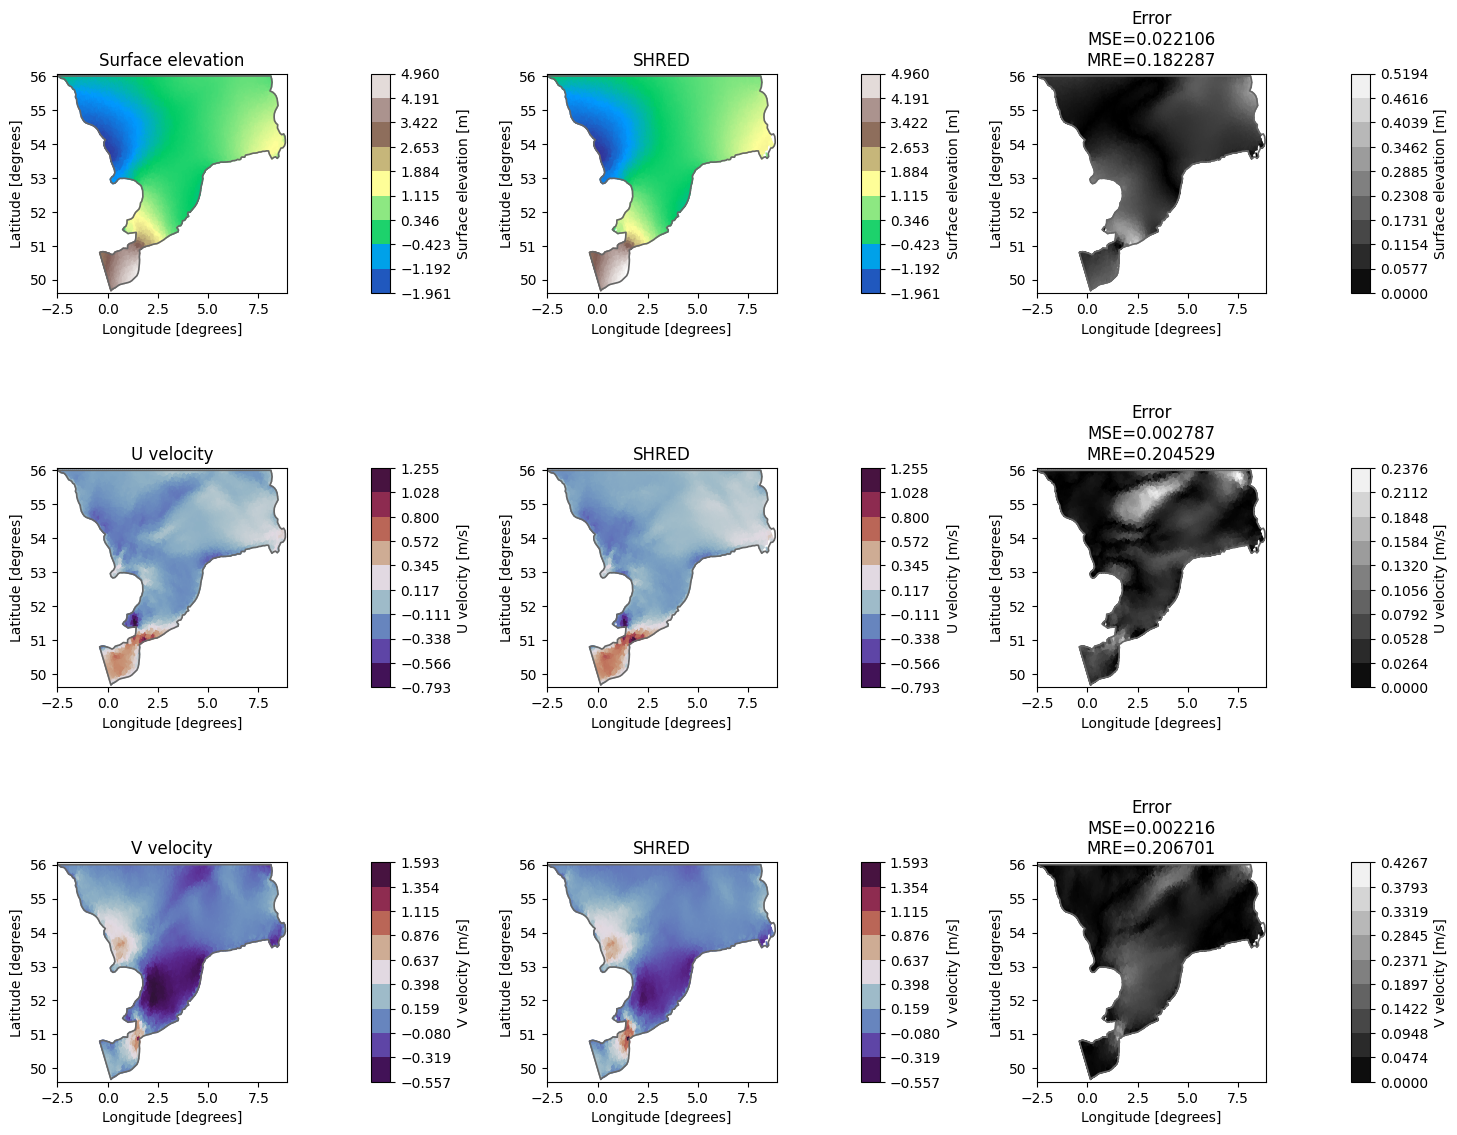

In [15]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.0)_always-available_stations_only")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error, kept_sensor_indices, removed_sensor_indices, measurements_av, manager

## (T.3.A): Masking

In [16]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 108507 

Residual energy of Surface elevation after keeping 12 modes: 0.1669 %
Residual energy of U velocity after keeping 40 modes: 0.1940 %
Residual energy of V velocity after keeping 68 modes: 0.1850 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 108507

Data shapes after preparation:
Train:	 torch.Size([25651, 48, 16]) -> torch.Size([25651, 120])
Val:	 torch.Size([3206, 48, 16]) -> torch.Size([3206, 120])
Test:	 torch.Size([3207, 48, 16]) -> torch.Size([3207, 120])

Input shape for the model: 16
Output shape for the model: 120


Starting SPARSE training...


Training:  20%|██        | 101/500 [17:56<1:10:51, 10.65s/it, Train Loss=0.02138, Val Loss=0.02003, Patience=99, Best Val Loss=0.00657, LR=9.01e-04, Sparse S/V/T=4.0/14.0/16]

Early stopping at epoch 102
Training completed with best validation loss: 0.0066


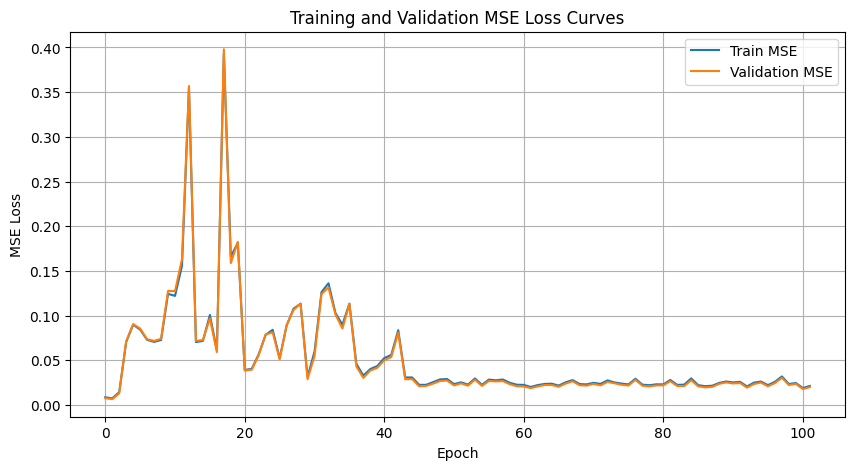

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.002524,0.003814,0.006619,0.103981,0.121077,0.150981
1,(mSHRED): TR+cnn,(T.3.A): masking,0.007493,0.006567,0.010249,0.180931,0.168933,0.201937


In [17]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = sparse_fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE, sparse_factor=SPARSE_FACTOR, sparse_log=SPARSE_LOG
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.A): masking", masking_type=MASKING_TYPE
)

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.3.A)_masking.png


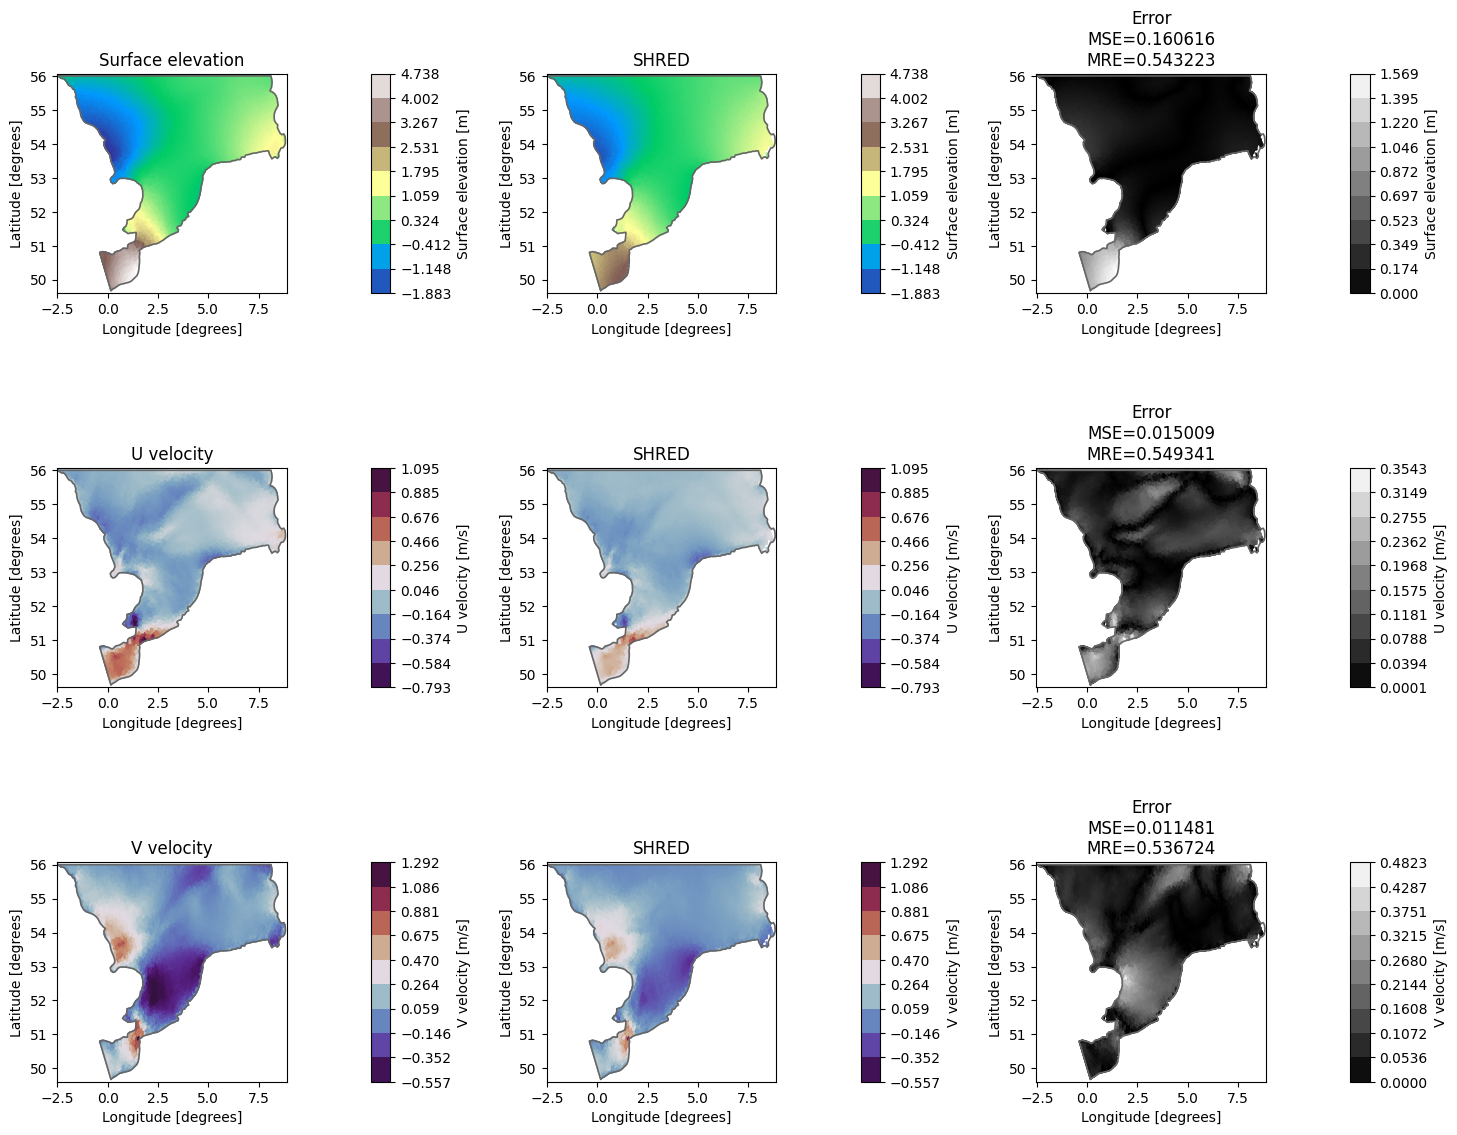

In [18]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.A)_masking")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.B): Masking x2 channels

Starting SPARSE training...


Training:  20%|██        | 102/500 [19:56<1:17:48, 11.73s/it, Train Loss=0.01734, Val Loss=0.01832, Patience=99, Best Val Loss=0.00620, LR=8.99e-04, Sparse S/V/T=4.0/14.0/16]

Early stopping at epoch 103
Training completed with best validation loss: 0.0062


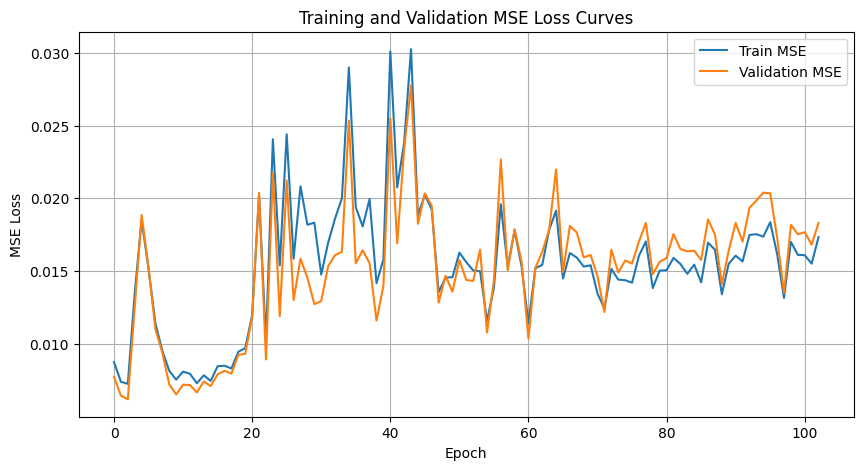

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.002524,0.003814,0.006619,0.103981,0.121077,0.150981
1,(mSHRED): TR+cnn,(T.3.A): masking,0.007493,0.006567,0.010249,0.180931,0.168933,0.201937
2,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.007261,0.006204,0.009916,0.177238,0.163166,0.197953


In [19]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = sparse_fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    sparse_factor=SPARSE_FACTOR, sparse_log=SPARSE_LOG,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.B): masking x2 channels", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.3.B)_masking_x2_channels.png


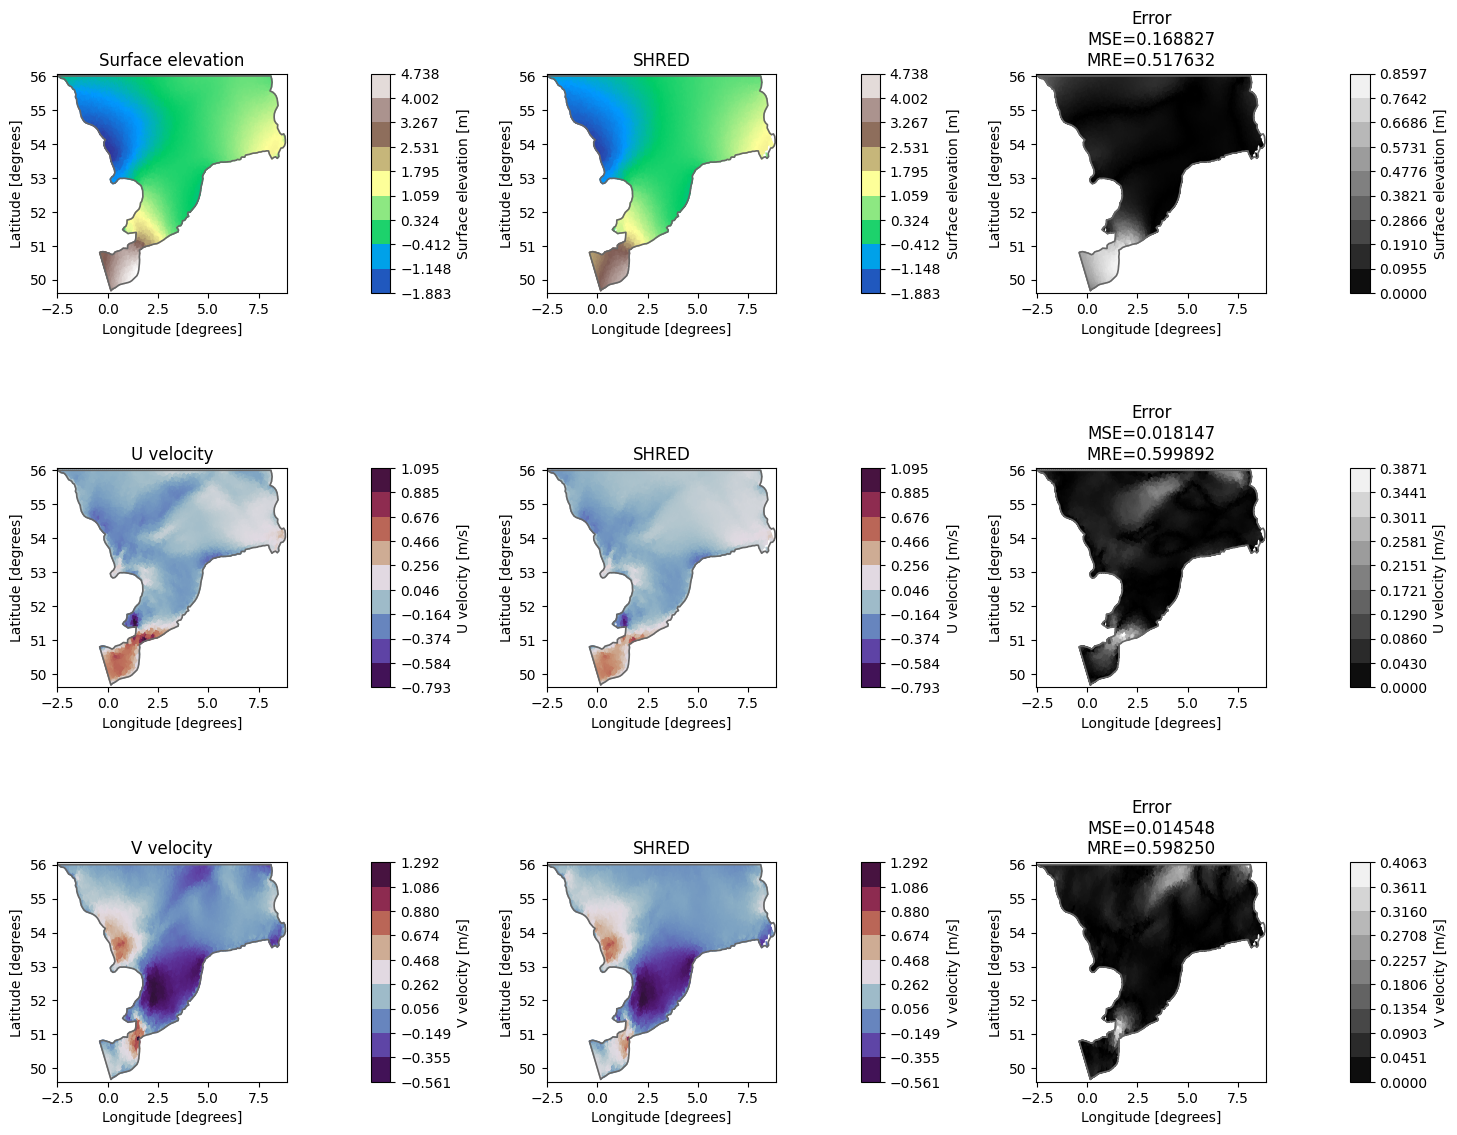

In [20]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.B)_masking_x2_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.C): Masking hidden space

Starting SPARSE training...


Training:  20%|██        | 101/500 [15:28<1:01:07,  9.19s/it, Train Loss=0.01543, Val Loss=0.01711, Patience=99, Best Val Loss=0.00755, LR=9.01e-04, Sparse S/V/T=4.0/14.0/16]

Early stopping at epoch 102
Training completed with best validation loss: 0.0076


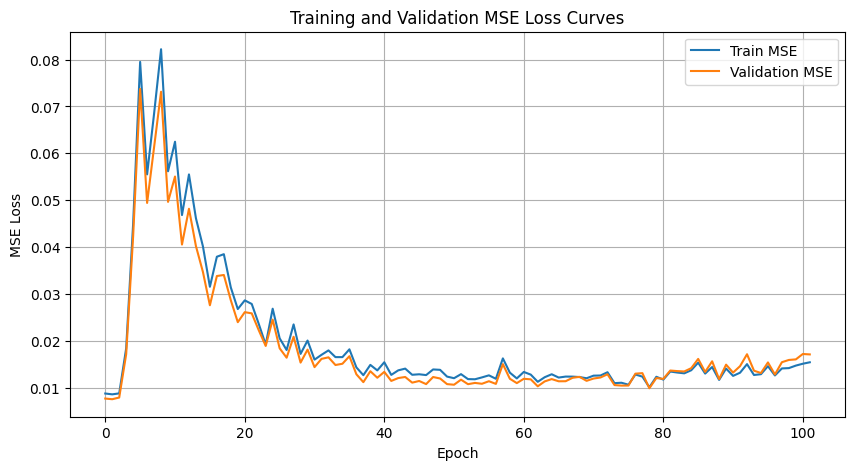

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.002524,0.003814,0.006619,0.103981,0.121077,0.150981
1,(mSHRED): TR+cnn,(T.3.A): masking,0.007493,0.006567,0.010249,0.180931,0.168933,0.201937
2,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.007261,0.006204,0.009916,0.177238,0.163166,0.197953
3,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.008590,0.007550,0.011350,0.195826,0.182506,0.215713


In [21]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = sparse_fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    sparse_factor=SPARSE_FACTOR, sparse_log=SPARSE_LOG,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.C): masking hidden space", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.3.C)_masking_hidden_space.png


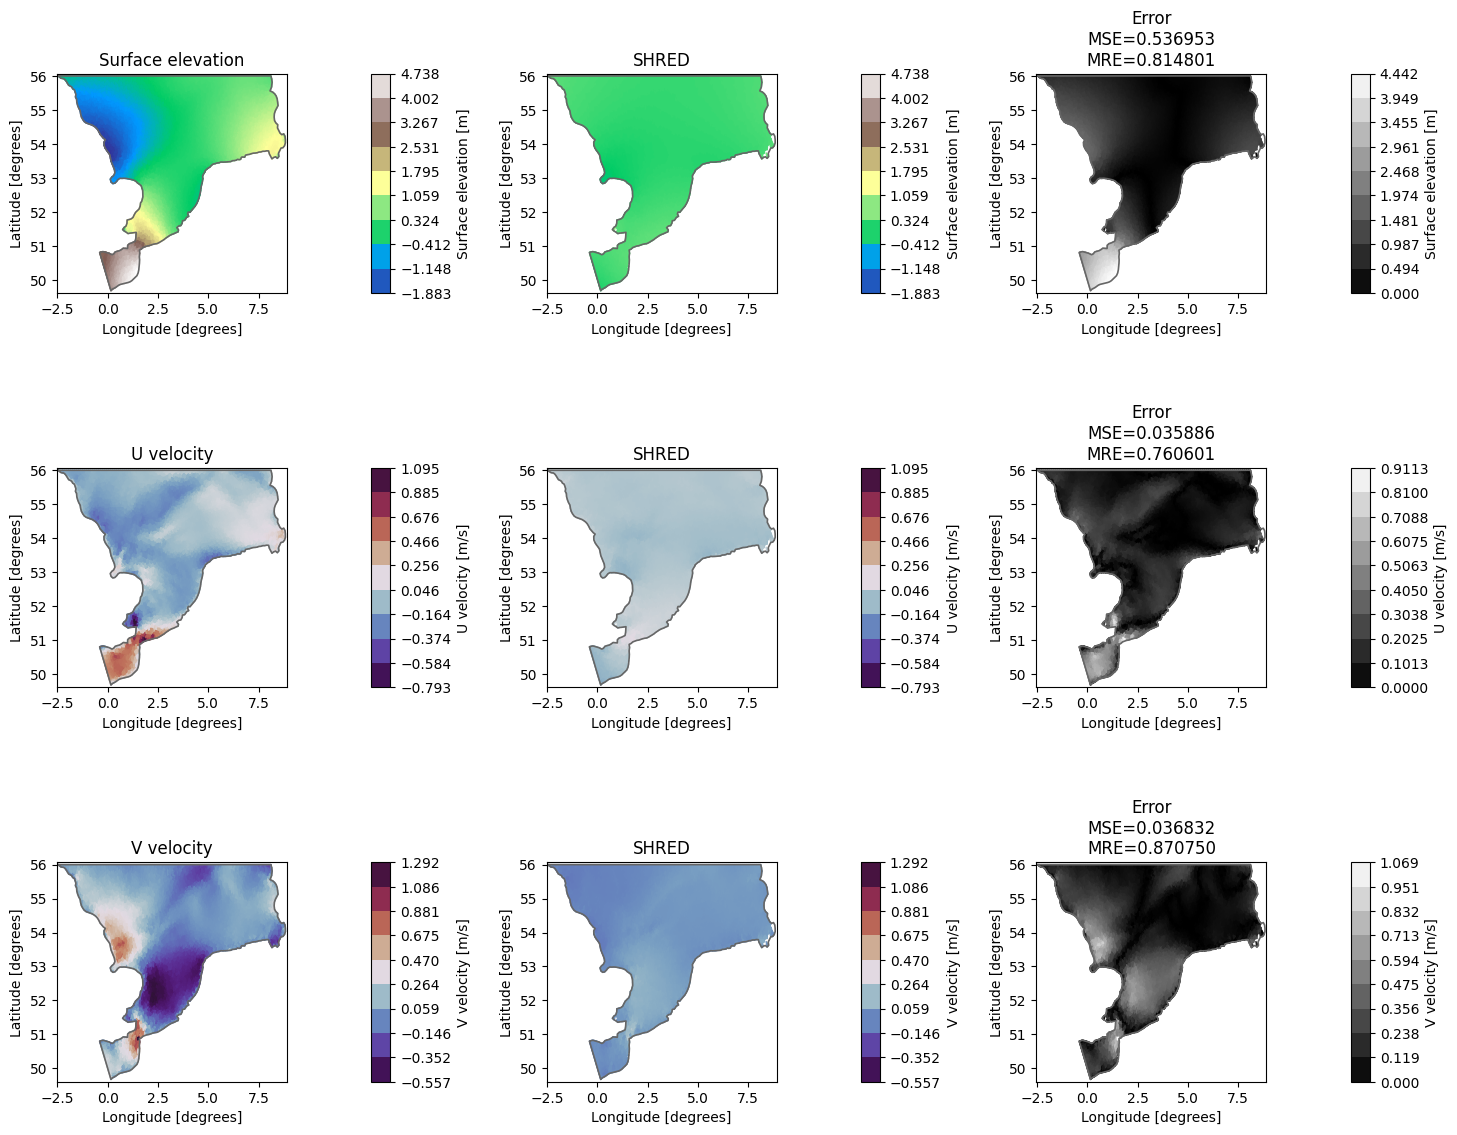

In [22]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.C)_masking_hidden_space")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.D): Masking MHSA

Starting SPARSE training...


Training:  20%|██        | 101/500 [15:47<1:02:23,  9.38s/it, Train Loss=0.01540, Val Loss=0.01437, Patience=99, Best Val Loss=0.00691, LR=9.01e-04, Sparse S/V/T=4.0/14.0/16]

Early stopping at epoch 102
Training completed with best validation loss: 0.0069


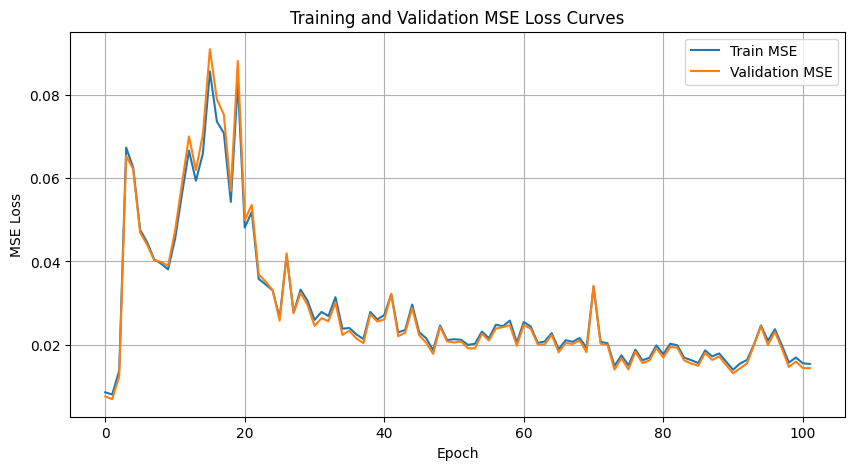

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.002524,0.003814,0.006619,0.103981,0.121077,0.150981
1,(mSHRED): TR+cnn,(T.3.A): masking,0.007493,0.006567,0.010249,0.180931,0.168933,0.201937
2,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.007261,0.006204,0.009916,0.177238,0.163166,0.197953
3,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.008590,0.007550,0.011350,0.195826,0.182506,0.215713
4,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.008061,0.006914,0.010548,0.188207,0.173510,0.205811


In [23]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = sparse_fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    sparse_factor=SPARSE_FACTOR, sparse_log=SPARSE_LOG,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.D): masking MHSA", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.3.D)_masking_MHSA.png


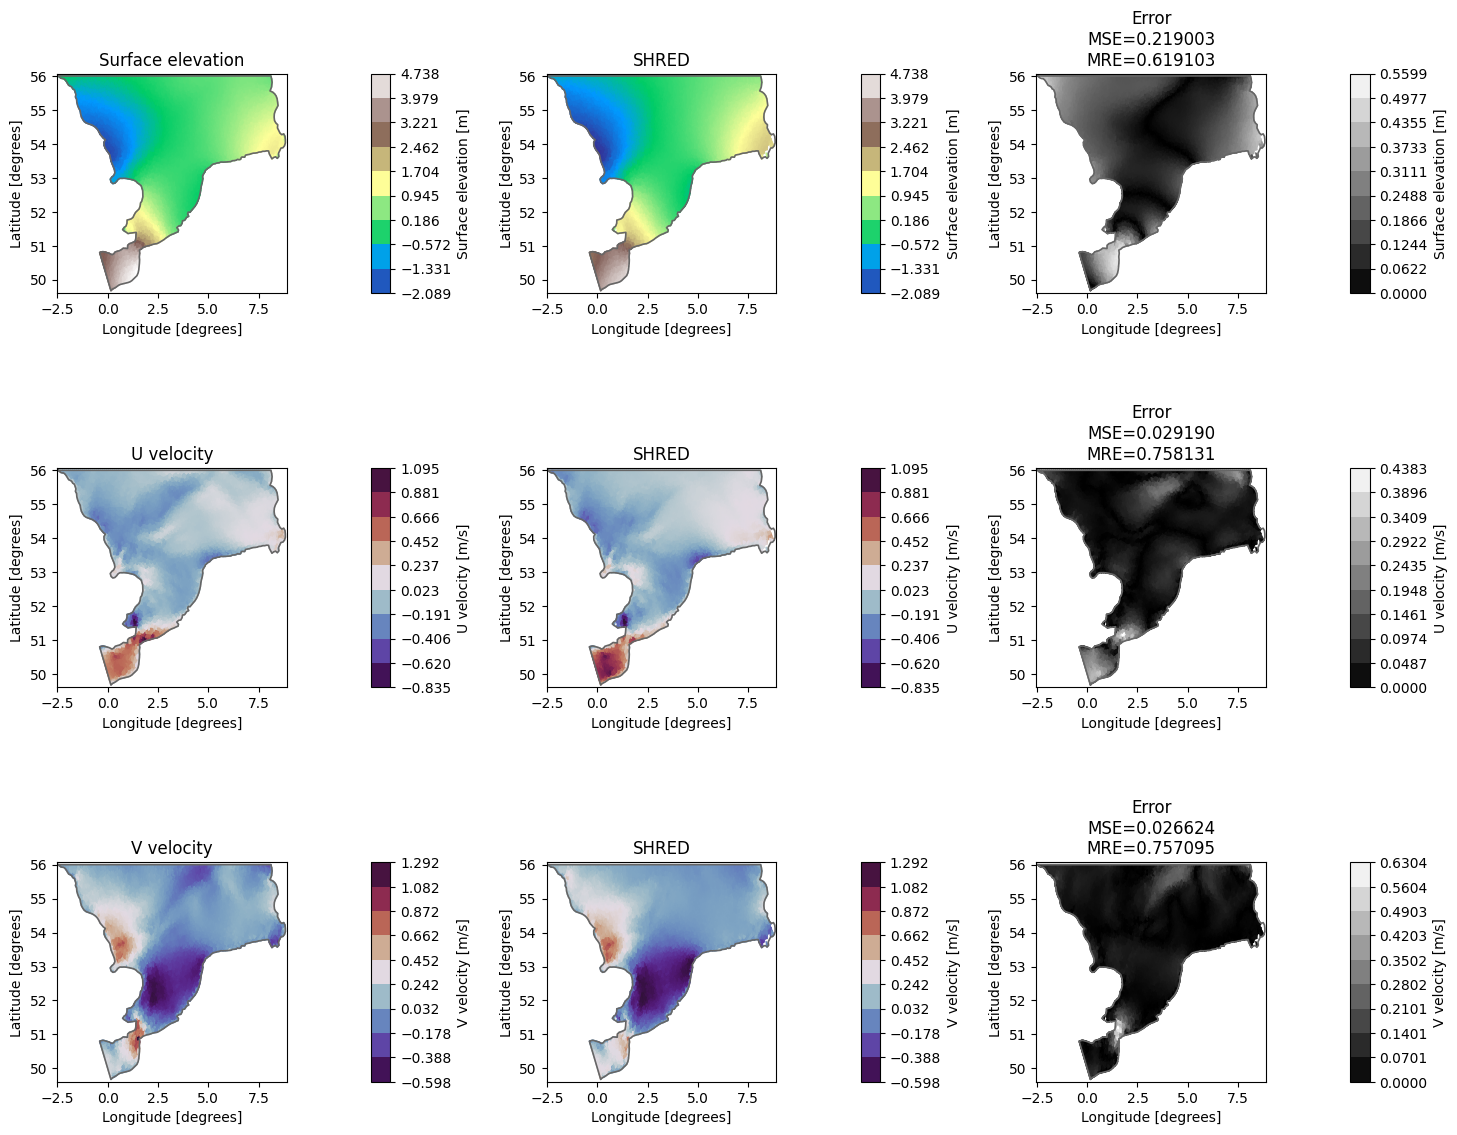

In [24]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.D)_masking_MHSA")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.E): Masking x2 channels + MHSA

Starting SPARSE training...


Training:  23%|██▎       | 113/500 [16:57<58:03,  9.00s/it, Train Loss=0.01142, Val Loss=0.01177, Patience=99, Best Val Loss=0.00636, LR=8.77e-04, Sparse S/V/T=4.0/14.0/16]  

Early stopping at epoch 114
Training completed with best validation loss: 0.0064


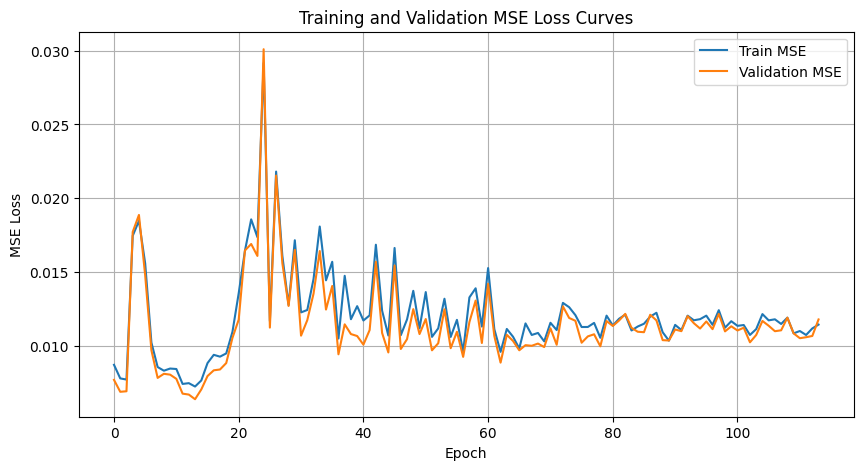

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.002524,0.003814,0.006619,0.103981,0.121077,0.150981
1,(mSHRED): TR+cnn,(T.3.A): masking,0.007493,0.006567,0.010249,0.180931,0.168933,0.201937
2,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.007261,0.006204,0.009916,0.177238,0.163166,0.197953
3,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.008590,0.007550,0.011350,0.195826,0.182506,0.215713
4,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.008061,0.006914,0.010548,0.188207,0.173510,0.205811
5,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.007219,0.006358,0.009907,0.177017,0.165164,0.198424


In [25]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = sparse_fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    sparse_factor=SPARSE_FACTOR, sparse_log=SPARSE_LOG,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.E): masking x2 channels + MHSA", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.3.E)_masking_x2_channels_MHSA.png


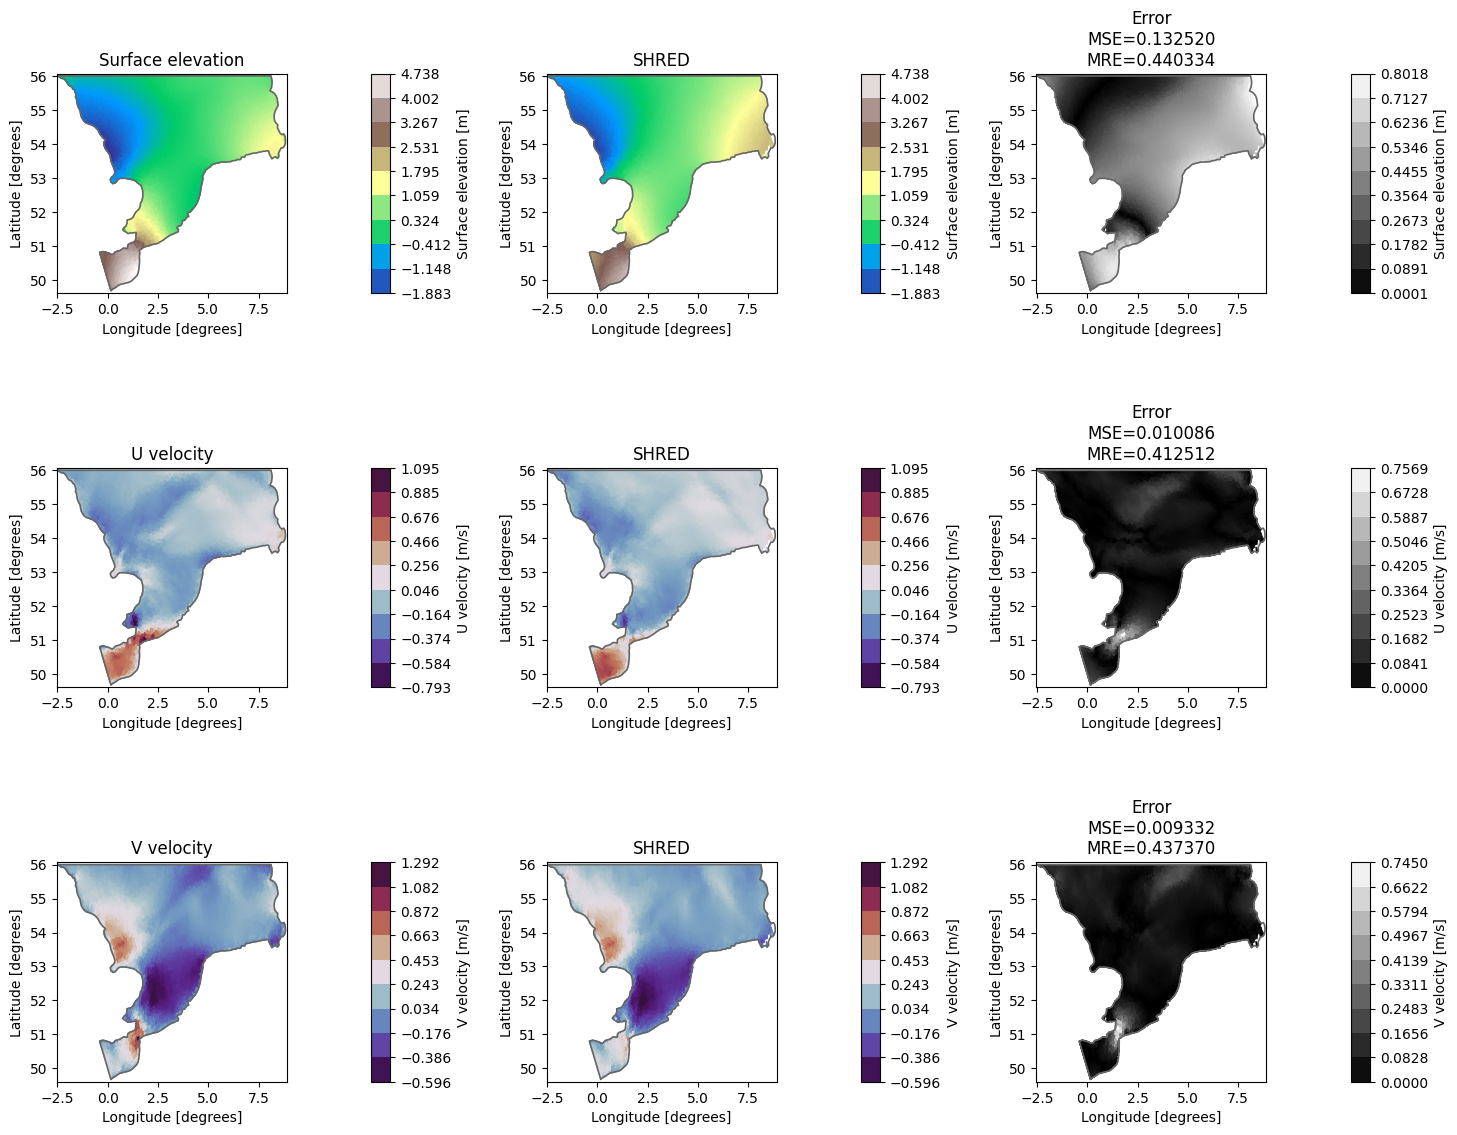

In [26]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.E)_masking_x2_channels_MHSA")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.F): Masking MHSA learned

Starting SPARSE training...


Training:  20%|██        | 101/500 [24:10<1:35:28, 14.36s/it, Train Loss=0.02337, Val Loss=0.02189, Patience=99, Best Val Loss=0.00679, LR=9.01e-04, Sparse S/V/T=4.0/14.0/16]

Early stopping at epoch 102
Training completed with best validation loss: 0.0068


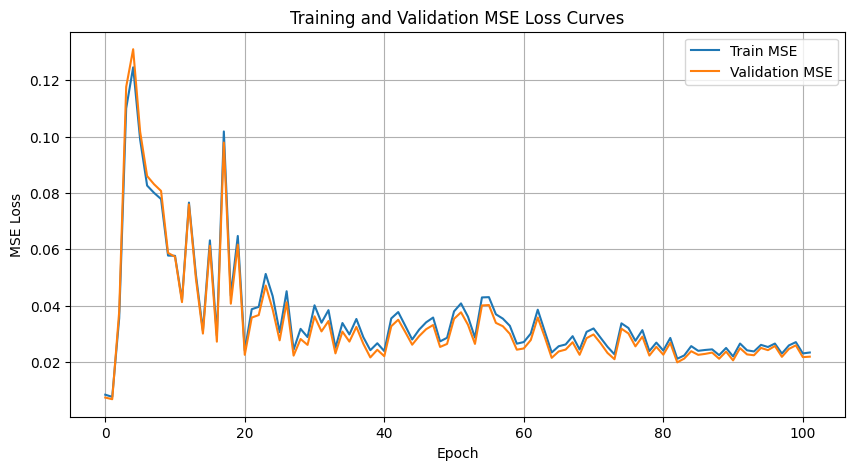

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.002524,0.003814,0.006619,0.103981,0.121077,0.150981
1,(mSHRED): TR+cnn,(T.3.A): masking,0.007493,0.006567,0.010249,0.180931,0.168933,0.201937
2,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.007261,0.006204,0.009916,0.177238,0.163166,0.197953
3,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.008590,0.007550,0.011350,0.195826,0.182506,0.215713
4,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.008061,0.006914,0.010548,0.188207,0.173510,0.205811
5,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.007219,0.006358,0.009907,0.177017,0.165164,0.198424
6,(mSHRED): TR+cnn,(T.3.F): masking MHSA learned,0.007625,0.006790,0.010594,0.182609,0.171899,0.206747


In [27]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = sparse_fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    sparse_factor=SPARSE_FACTOR, sparse_log=SPARSE_LOG,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.F): masking MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.3.F)_masking_MHSA_learned.png


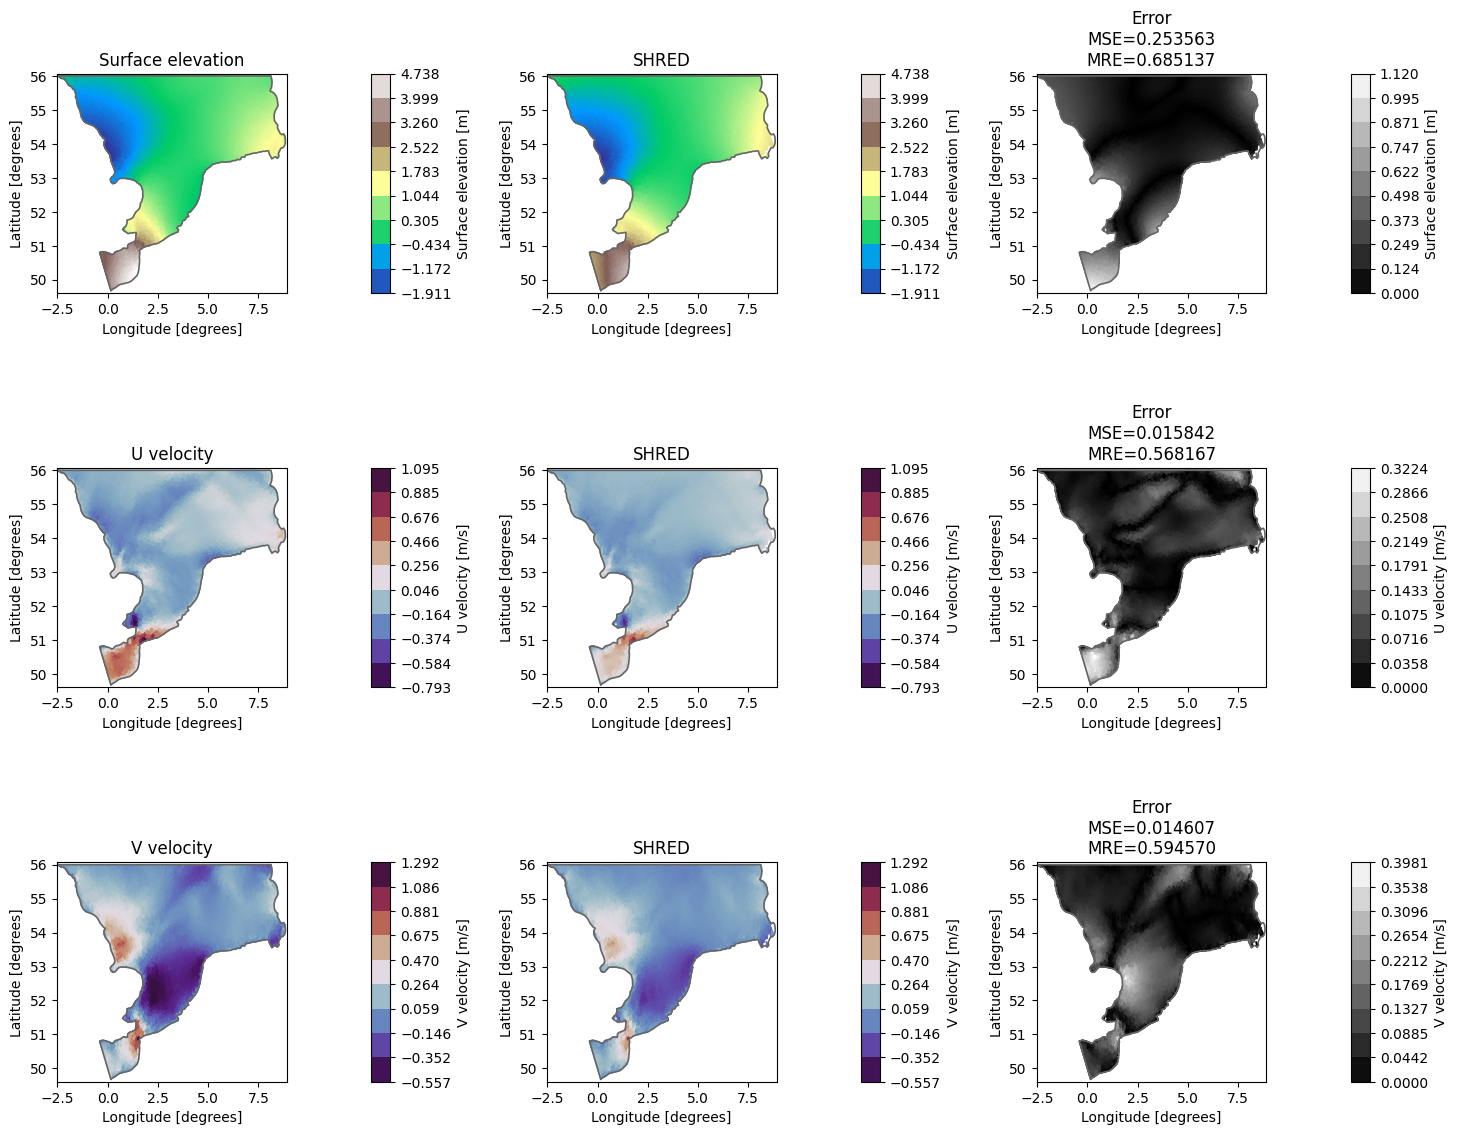

In [28]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.F)_masking_MHSA_learned")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.G): Masking x2 channels + MHSA learned

Starting SPARSE training...


Training:  20%|██        | 101/500 [24:47<1:37:55, 14.73s/it, Train Loss=0.02552, Val Loss=0.02455, Patience=99, Best Val Loss=0.00710, LR=9.01e-04, Sparse S/V/T=4.0/14.0/16]

Early stopping at epoch 102
Training completed with best validation loss: 0.0071


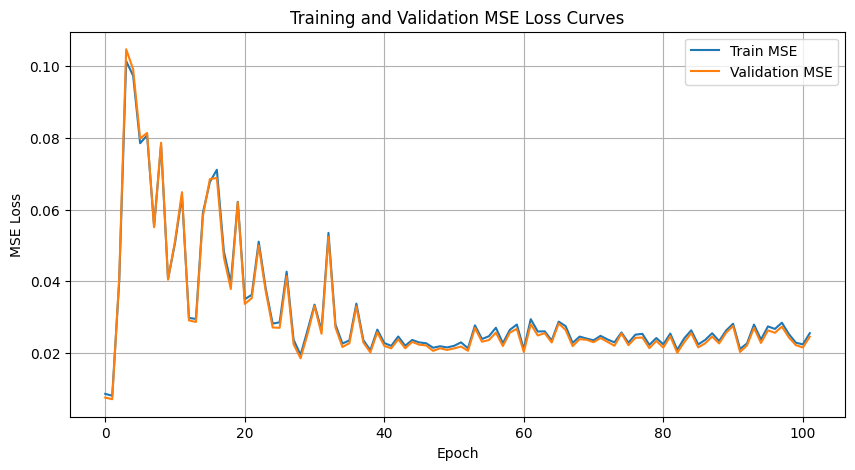

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.002524,0.003814,0.006619,0.103981,0.121077,0.150981
1,(mSHRED): TR+cnn,(T.3.A): masking,0.007493,0.006567,0.010249,0.180931,0.168933,0.201937
2,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.007261,0.006204,0.009916,0.177238,0.163166,0.197953
3,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.008590,0.007550,0.011350,0.195826,0.182506,0.215713
4,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.008061,0.006914,0.010548,0.188207,0.173510,0.205811
5,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.007219,0.006358,0.009907,0.177017,0.165164,0.198424
6,(mSHRED): TR+cnn,(T.3.F): masking MHSA learned,0.007625,0.006790,0.010594,0.182609,0.171899,0.206747
7,(mSHRED): TR+cnn,(T.3.G): masking x2 channels + MHSA learned,0.008076,0.007103,0.010872,0.189100,0.176635,0.210500


In [29]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = sparse_fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    sparse_factor=SPARSE_FACTOR, sparse_log=SPARSE_LOG,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.G): masking x2 channels + MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.3.G)_masking_x2_channels_MHSA_learned.png


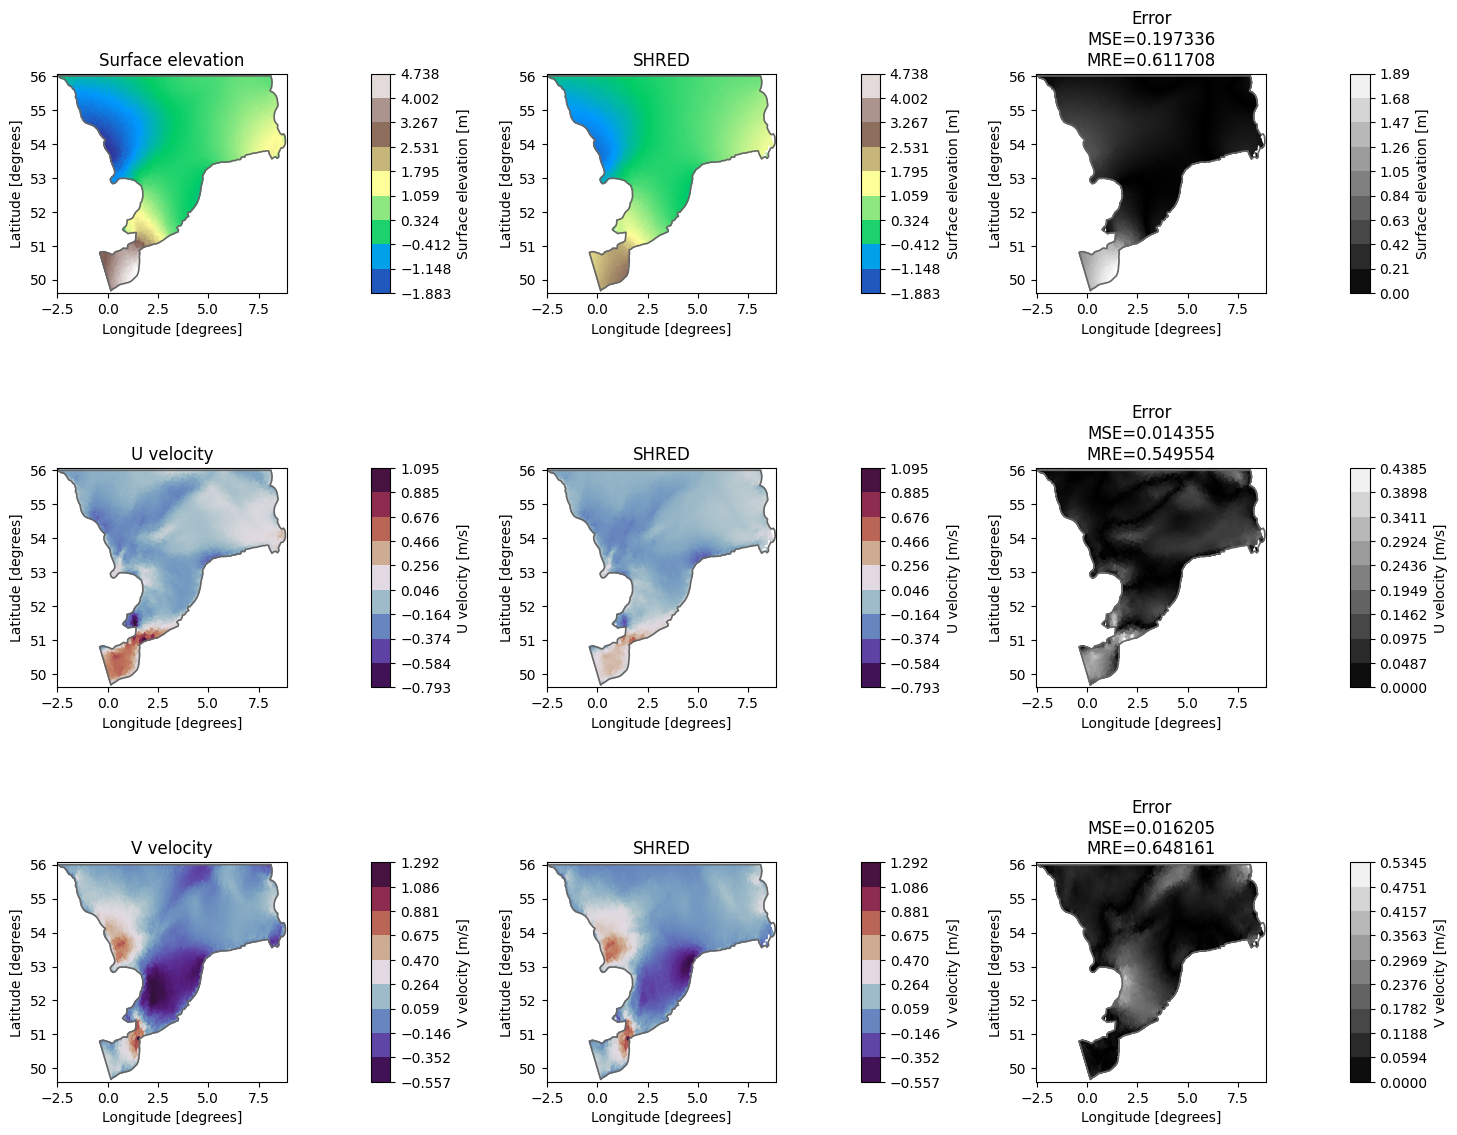

In [30]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.G)_masking_x2_channels_MHSA_learned")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## Results

In [31]:
dataframe_errors = pd.read_csv("dataframe_errors.csv")  # reload to ensure clean data
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.002524,0.003814,0.006619,0.103981,0.121077,0.150981
1,(mSHRED): TR+cnn,(T.3.A): masking,0.007493,0.006567,0.010249,0.180931,0.168933,0.201937
2,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.007261,0.006204,0.009916,0.177238,0.163166,0.197953
3,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.008590,0.007550,0.011350,0.195826,0.182506,0.215713
4,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.008061,0.006914,0.010548,0.188207,0.173510,0.205811
5,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.007219,0.006358,0.009907,0.177017,0.165164,0.198424
6,(mSHRED): TR+cnn,(T.3.F): masking MHSA learned,0.007625,0.006790,0.010594,0.182609,0.171899,0.206747
7,(mSHRED): TR+cnn,(T.3.G): masking x2 channels + MHSA learned,0.008076,0.007103,0.010872,0.189100,0.176635,0.210500


In [32]:
# order dataframe by test-mre
print("\nFinal comparison of all models, ordered by test MRE:")
dataframe_errors = dataframe_errors.sort_values(by="test-mre")
display(dataframe_errors)


Final comparison of all models, ordered by test MRE:


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.002524,0.003814,0.006619,0.103981,0.121077,0.150981
2,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.007261,0.006204,0.009916,0.177238,0.163166,0.197953
5,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.007219,0.006358,0.009907,0.177017,0.165164,0.198424
1,(mSHRED): TR+cnn,(T.3.A): masking,0.007493,0.006567,0.010249,0.180931,0.168933,0.201937
4,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.008061,0.006914,0.010548,0.188207,0.173510,0.205811
6,(mSHRED): TR+cnn,(T.3.F): masking MHSA learned,0.007625,0.006790,0.010594,0.182609,0.171899,0.206747
7,(mSHRED): TR+cnn,(T.3.G): masking x2 channels + MHSA learned,0.008076,0.007103,0.010872,0.189100,0.176635,0.210500
3,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.008590,0.007550,0.011350,0.195826,0.182506,0.215713


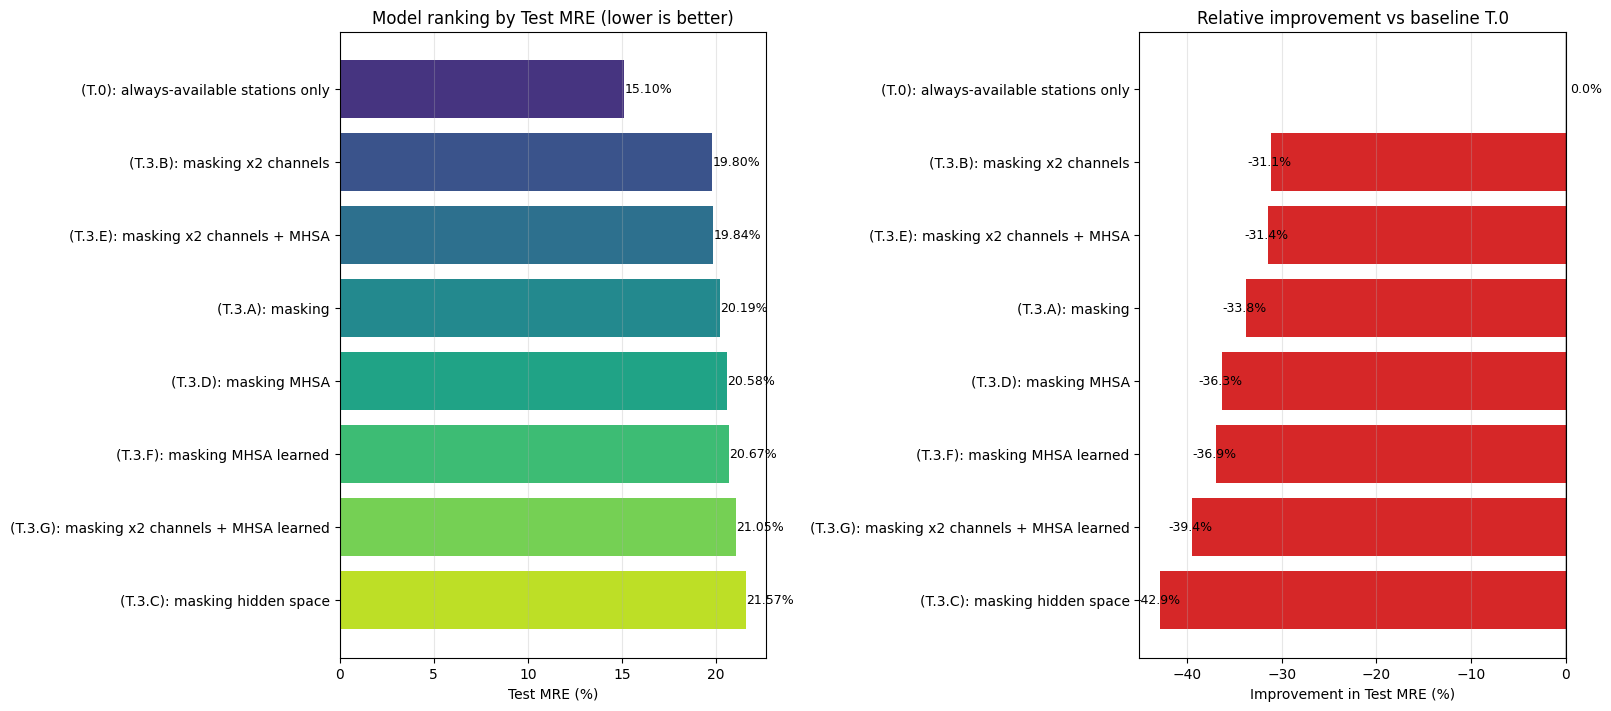

In [33]:
# Meaningful summary plot: ranking + improvement vs baseline
df_plot = dataframe_errors.sort_values("test-mre").reset_index(drop=True)

# Baseline = T.0 (only available sensors)
baseline_mask = df_plot["type"].str.contains("T.0", regex=False)
baseline_test_mre = df_plot.loc[baseline_mask, "test-mre"].iloc[0] if baseline_mask.any() else df_plot["test-mre"].max()

# Keep raw values for ratio math, but plot MRE on a 0-100% scale
df_plot["test-mre_%"] = 100 * df_plot["test-mre"]
df_plot["improvement_vs_T0_%"] = 100 * (baseline_test_mre - df_plot["test-mre"]) / baseline_test_mre

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)

# --- Left: Test MRE ranking (%) ---
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(df_plot)))
axes[0].barh(df_plot["type"], df_plot["test-mre_%"], color=colors)
axes[0].invert_yaxis()
axes[0].set_title("Model ranking by Test MRE (lower is better)")
axes[0].set_xlabel("Test MRE (%)")
axes[0].grid(axis="x", alpha=0.3)

for i, v in enumerate(df_plot["test-mre_%"]):
    axes[0].text(v + 0.03, i, f"{v:.2f}%", va="center", fontsize=9)

# --- Right: Improvement vs baseline (T.0) ---
imp_colors = ["tab:green" if x >= 0 else "tab:red" for x in df_plot["improvement_vs_T0_%"]]
axes[1].barh(df_plot["type"], df_plot["improvement_vs_T0_%"], color=imp_colors)
axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Relative improvement vs baseline T.0")
axes[1].set_xlabel("Improvement in Test MRE (%)")
axes[1].grid(axis="x", alpha=0.3)

for i, v in enumerate(df_plot["improvement_vs_T0_%"]):
    axes[1].text(v + (0.4 if v >= 0 else -2.5), i, f"{v:.1f}%", va="center", fontsize=9)

plt.show()

## Run1: Sparse sensors

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.0): always-available stations only</td>
      <td>0.002524</td>
      <td>0.003814</td>
      <td>0.006619</td>
      <td>0.103981</td>
      <td>0.121077</td>
      <td>0.150981</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.B): masking x2 channels</td>
      <td>0.007261</td>
      <td>0.006204</td>
      <td>0.009916</td>
      <td>0.177238</td>
      <td>0.163166</td>
      <td>0.197953</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.E): masking x2 channels + MHSA</td>
      <td>0.007219</td>
      <td>0.006358</td>
      <td>0.009907</td>
      <td>0.177017</td>
      <td>0.165164</td>
      <td>0.198424</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.A): masking</td>
      <td>0.007493</td>
      <td>0.006567</td>
      <td>0.010249</td>
      <td>0.180931</td>
      <td>0.168933</td>
      <td>0.201937</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.D): masking MHSA</td>
      <td>0.008061</td>
      <td>0.006914</td>
      <td>0.010548</td>
      <td>0.188207</td>
      <td>0.173510</td>
      <td>0.205811</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.F): masking MHSA learned</td>
      <td>0.007625</td>
      <td>0.006790</td>
      <td>0.010594</td>
      <td>0.182609</td>
      <td>0.171899</td>
      <td>0.206747</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.G): masking x2 channels + MHSA learned</td>
      <td>0.008076</td>
      <td>0.007103</td>
      <td>0.010872</td>
      <td>0.189100</td>
      <td>0.176635</td>
      <td>0.210500</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.C): masking hidden space</td>
      <td>0.008590</td>
      <td>0.007550</td>
      <td>0.011350</td>
      <td>0.195826</td>
      <td>0.182506</td>
      <td>0.215713</td>
    </tr>
  </tbody>
</table>
</div>

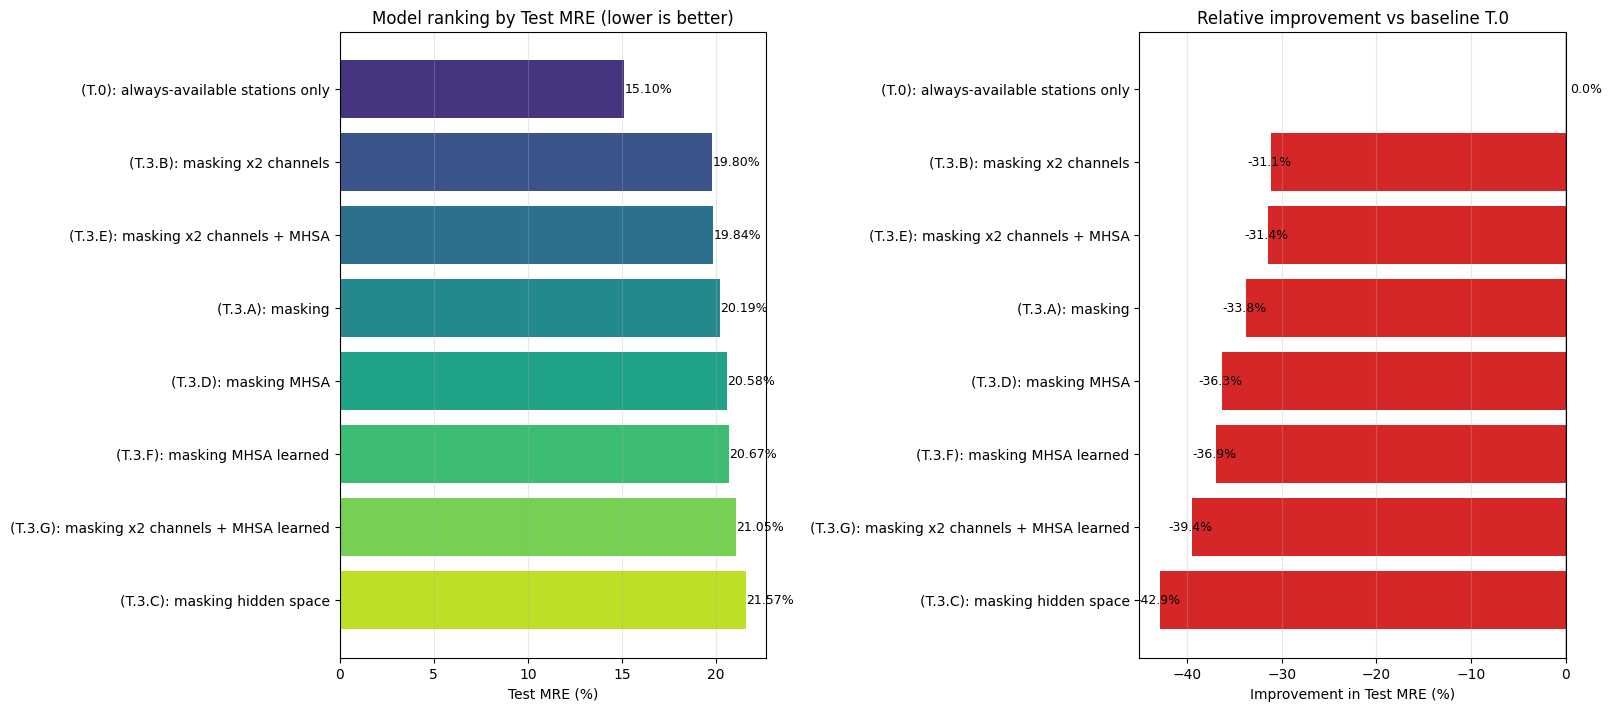